# Лабораторная работа 3. Корреляции и влияние пар факторов на целевую переменную

**Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ**
Дисциплина «Разведочный анализ и алгоритмы классификации»

**Этап CRISP-DM:** Data understanding (продолжение lab2). Датасет тот же — Online Shoppers Purchasing Intention.

**Цель:** измерить согласованность признаков между собой и с целевой переменной `Revenue` разными коэффициентами, понять, чем коэффициенты отличаются на этих данных, и описать, как целевая переменная распределена по сочетаниям двух признаков.

**Задачи:**
1. Посчитать и сравнить коэффициенты Пирсона, Спирмена и Кендалла для числовых признаков.
2. Для категориальных признаков посчитать V Крамера, для пар «числовой — категориальный» — корреляционное отношение η.
3. Построить единую матрицу φK (phik), пригодную для признаков любых типов.
4. Найти сильно согласованные пары признаков (мультиколлинеарность).
5. Исследовать долю покупок в сочетаниях двух признаков (тепловые карты, диаграммы рассеяния) и измерить, насколько пара признаков вместе описывает `Revenue` по сравнению с каждым признаком отдельно.

> Как и в lab2, здесь фиксирую только наблюдаемое. Коэффициент корреляции описывает согласованность значений в выборке и ничего не говорит о причинах.

### Какие коэффициенты используются и чем они отличаются

| Коэффициент | Для каких признаков | Что измеряет | Особенности |
|---|---|---|---|
| Пирсона $r$ | числовые | линейную связь | чувствителен к выбросам и скошенности; для бинарного признака совпадает с точечно-бисериальным |
| Спирмена $\rho$ | числовые, порядковые | монотонную связь (Пирсон по рангам) | устойчив к выбросам, не меняется при монотонных преобразованиях (`log1p`) |
| Кендалла $\tau_b$ | числовые, порядковые | долю согласованных пар минус долю несогласованных | по модулю обычно меньше $\rho$; учитывает связки (одинаковые значения) — важно при большом числе нулей |
| V Крамера | номинальные | силу связи по χ² таблицы сопряжённости, 0…1 | без направления; используется версия с поправкой на смещение (Bergsma, 2013) |
| η (корреляционное отношение) | числовой × номинальный | долю дисперсии числового признака, объяснённую группами | 0…1, несимметричен |
| φK (phik) | любые | обобщение корреляции на основе двумерного нормального распределения | 0…1, ловит нелинейные зависимости; числовые признаки предварительно бинируются |

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy import stats
from matplotlib.ticker import PercentFormatter
import phik  # noqa: F401  (регистрирует df.phik_matrix)

from src.data import load, NUMERIC, NOMINAL, TARGET, MONTH_ORDER, MONTH_RU
from src import viz
viz.setup()
pd.set_option("display.width", 160)

df = load()
num_cols = NUMERIC + [TARGET]
print(df.shape)

(12330, 18)


## 1. Пирсон, Спирмен, Кендалл для числовых признаков
Целевая переменная (0/1) включена в матрицы как ещё один столбец.

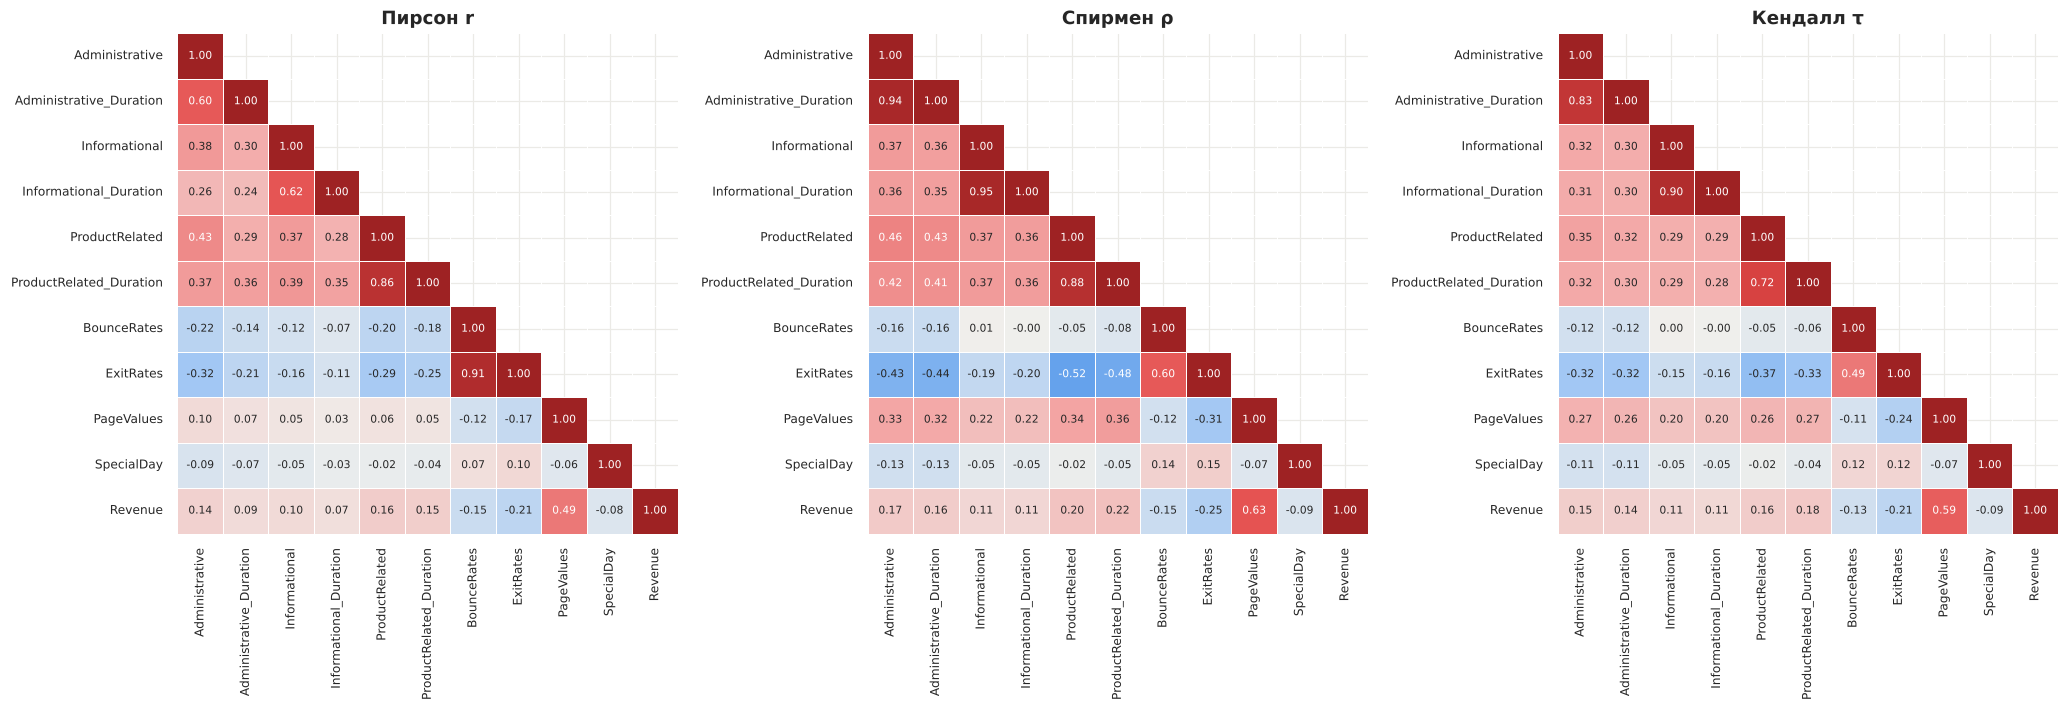

In [2]:
X = df[num_cols].astype(float)
corr = {m: X.corr(method=m) for m in ["pearson", "spearman", "kendall"]}
names = {"pearson": "Пирсон r", "spearman": "Спирмен ρ", "kendall": "Кендалл τ"}

fig, axes = plt.subplots(1, 3, figsize=(19, 6.2))
mask = np.triu(np.ones_like(corr["pearson"], dtype=bool), k=1)
for a, m in zip(axes, corr):
    sns.heatmap(corr[m], mask=mask, cmap=viz.DIV, vmin=-1, vmax=1, annot=True, fmt=".2f",
                annot_kws={"size": 7}, linewidths=0.5, linecolor="white", cbar=False, square=True, ax=a)
    a.set_title(names[m])
    a.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

**Что видно на трёх матрицах.**
* **Пары «число страниц — время на них»** согласованы сильнее всего. По Спирмену: `Informational`–`Informational_Duration` 0,95, `Administrative`–`Administrative_Duration` 0,94, `ProductRelated`–`ProductRelated_Duration` 0,88. По Пирсону первые две пары заметно слабее (0,62 и 0,60): длинные хвосты и большое число нулей «ломают» линейную меру, а ранговая их не замечает.
* **`BounceRates`–`ExitRates`** — обратная ситуация: Пирсон 0,91, а Спирмен 0,60 и Кендалл 0,49. На диаграмме рассеяния ниже видно, откуда это: 700 сессий лежат в одной точке (0,2; 0,2), и эта «гиря» в углу сильно поднимает линейный коэффициент.
* `ExitRates` отрицательно согласован со всеми счётчиками и длительностями (ρ от −0,19 до −0,52); по Пирсону те же пары слабее (от −0,11 до −0,32).
* Кендалл по модулю везде меньше Спирмена (например, 0,83 против 0,94 для пары `Administrative`–`Administrative_Duration`) — это свойство самих коэффициентов, а не данных: τ — разность долей согласованных и несогласованных пар, его шкала другая.
* С `Revenue` сильнее всего согласован `PageValues` (r = 0,49, ρ = 0,63, τ = 0,59), затем `ExitRates` (ρ = −0,25).

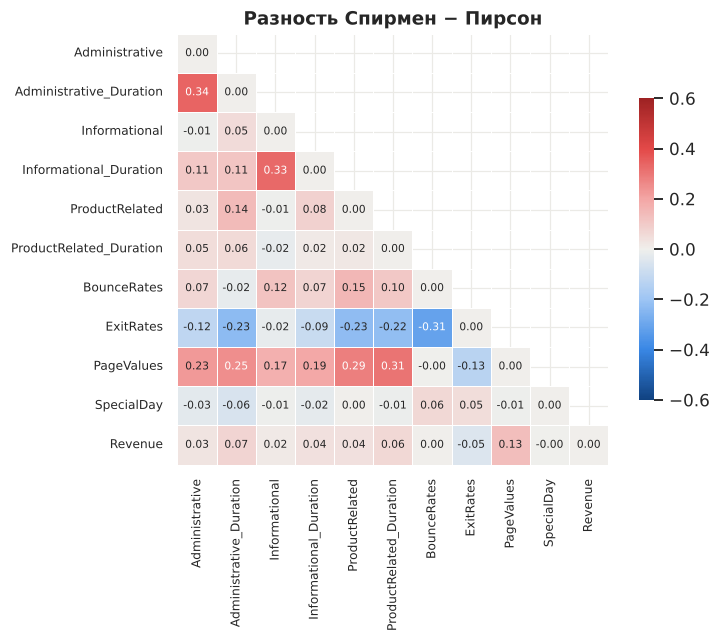

In [3]:
diff = corr["spearman"] - corr["pearson"]
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(diff, mask=mask, cmap=viz.DIV, vmin=-0.6, vmax=0.6, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.5, linecolor="white", square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Разность Спирмен − Пирсон"); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

Как читать разность: для положительных связей «+» означает, что Спирмен сильнее Пирсона; для отрицательных связей (все пары с `ExitRates`, кроме `BounceRates`) «−» означает то же самое — ρ по модулю больше.
* Пары счётчиков и длительностей между собой и с `PageValues`: разность до +0,34 (`Administrative`–`Administrative_Duration`), +0,33 (`Informational`–`Informational_Duration`), +0,31 (`ProductRelated_Duration`–`PageValues`).
* `ExitRates` со счётчиками и длительностями: разность от −0,12 до −0,23, т. е. по Спирмену эти отрицательные связи сильнее.
* Единственная пара, где Пирсон заметно **сильнее** Спирмена, — `BounceRates`–`ExitRates` (−0,31 при положительной связи).

На этих данных выбор коэффициента меняет картину: Пирсон недооценивает монотонные, но нелинейные зависимости на скошенных признаках и переоценивает пару, где есть скопление одинаковых крайних значений. Поэтому дальше опираюсь в первую очередь на ранговые коэффициенты и φK.

In [4]:
pairs = []
for a_, b_ in combinations(NUMERIC, 2):
    pairs.append({"признак 1": a_, "признак 2": b_,
                  "Пирсон": corr["pearson"].loc[a_, b_], "Спирмен": corr["spearman"].loc[a_, b_],
                  "Кендалл": corr["kendall"].loc[a_, b_]})
pairs = pd.DataFrame(pairs)
top_pairs = pairs.reindex(pairs["Спирмен"].abs().sort_values(ascending=False).index).head(10).reset_index(drop=True)
top_pairs.style.format(precision=3).background_gradient(subset=["Пирсон", "Спирмен", "Кендалл"], cmap=viz.DIV, vmin=-1, vmax=1)

,признак 1,признак 2,Пирсон,Спирмен,Кендалл
0,Informational,Informational_Duration,0.619,0.951,0.899
1,Administrative,Administrative_Duration,0.602,0.941,0.825
2,ProductRelated,ProductRelated_Duration,0.861,0.883,0.720
3,BounceRates,ExitRates,0.913,0.602,0.493
4,ProductRelated,ExitRates,-0.293,-0.519,-0.368
5,ProductRelated_Duration,ExitRates,-0.252,-0.477,-0.334
6,Administrative,ProductRelated,0.431,0.460,0.349
7,Administrative_Duration,ExitRates,-0.206,-0.438,-0.317
8,Administrative,ExitRates,-0.316,-0.434,-0.320
9,Administrative_Duration,ProductRelated,0.289,0.430,0.317


Десять самых согласованных пар числовых признаков (по |ρ|). Первые четыре пары имеют |ρ| ≥ 0,6 — это кандидаты на мультиколлинеарность. Для деревьев это не проблема, а для логистической регрессии означает неустойчивость отдельных коэффициентов; там помогает L2-регуляризация (lab5).

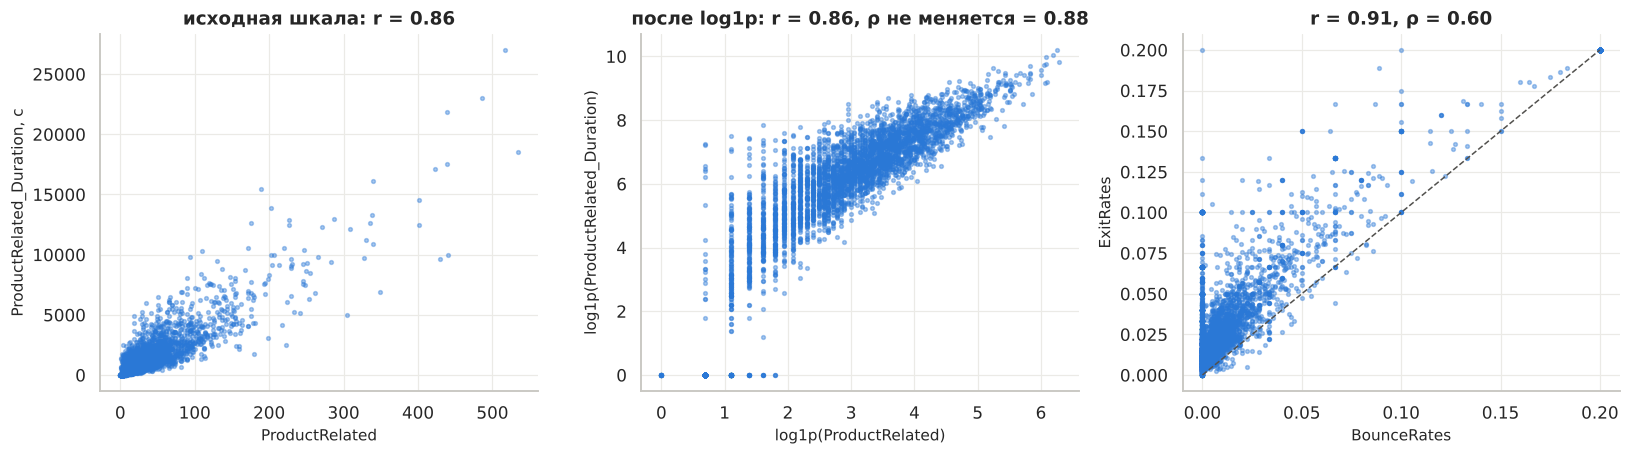

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
s = df.sample(4000, random_state=0)
cl = viz.class_name(s[TARGET])
col = [viz.CLASS_COLORS[c] for c in cl]
# 1) исходная шкала
axes[0].scatter(s["ProductRelated"], s["ProductRelated_Duration"], s=6, alpha=0.4, c=viz.BLUE)
axes[0].set_xlabel("ProductRelated"); axes[0].set_ylabel("ProductRelated_Duration, с")
axes[0].set_title(f"исходная шкала: r = {df['ProductRelated'].corr(df['ProductRelated_Duration']):.2f}")
# 2) логарифмическая шкала
lx, ly = np.log1p(df["ProductRelated"]), np.log1p(df["ProductRelated_Duration"])
axes[1].scatter(np.log1p(s["ProductRelated"]), np.log1p(s["ProductRelated_Duration"]), s=6, alpha=0.4, c=viz.BLUE)
axes[1].set_xlabel("log1p(ProductRelated)"); axes[1].set_ylabel("log1p(ProductRelated_Duration)")
axes[1].set_title(f"после log1p: r = {lx.corr(ly):.2f}, ρ не меняется = {corr['spearman'].loc['ProductRelated','ProductRelated_Duration']:.2f}")
# 3) BounceRates vs ExitRates
axes[2].scatter(s["BounceRates"], s["ExitRates"], s=6, alpha=0.4, c=viz.BLUE)
axes[2].plot([0, .2], [0, .2], ls="--", c="#52514e", lw=1)
axes[2].set_xlabel("BounceRates"); axes[2].set_ylabel("ExitRates")
axes[2].set_title(f"r = {corr['pearson'].loc['BounceRates','ExitRates']:.2f}, ρ = {corr['spearman'].loc['BounceRates','ExitRates']:.2f}")
plt.tight_layout(); plt.show()

* Слева: в исходной шкале облако `ProductRelated` × `ProductRelated_Duration` сжато в углу, несколько сессий с сотнями страниц определяют наклон.
* В центре: после `log1p` облако вытянуто вдоль диагонали, видны вертикальные «полосы» на малых целых значениях числа страниц и горизонтальная линия нулевого времени. Коэффициент Пирсона на этой паре почти не изменился (0,86 → 0,86), а Спирмен по построению не зависит от монотонного преобразования.
* Справа: большинство точек лежит **выше** диагонали (`ExitRates` ≥ `BounceRates`), отдельно видны скопление в (0,2; 0,2) и вертикальная полоса при `BounceRates` = 0.

## 2. Согласованность числовых признаков с целевой переменной

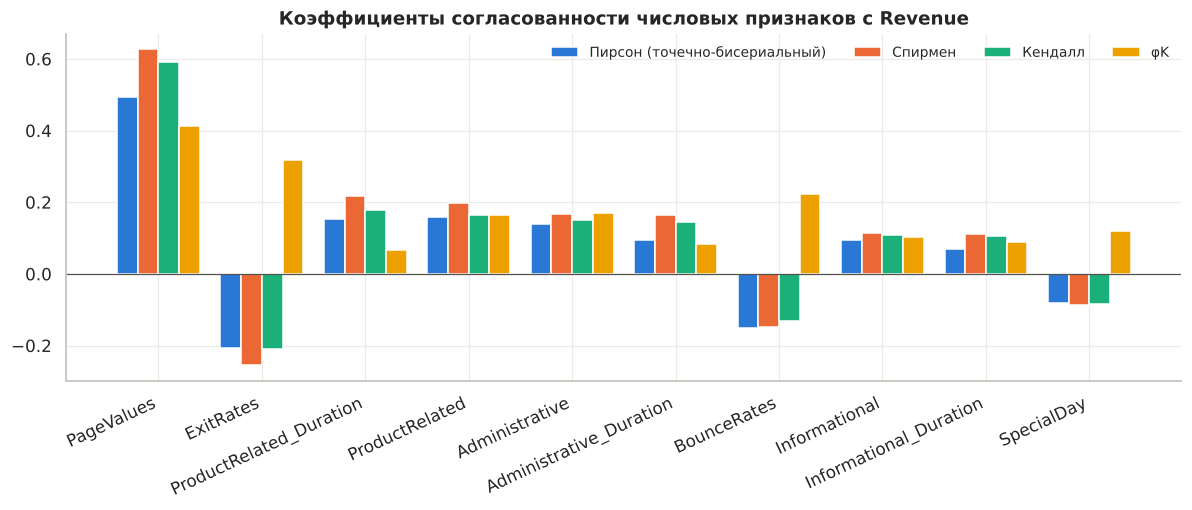

,Пирсон (точечно-бисериальный),Спирмен,Кендалл,φK
PageValues,0.493,0.626,0.592,0.413
ExitRates,-0.207,-0.254,-0.209,0.319
ProductRelated_Duration,0.152,0.217,0.177,0.067
ProductRelated,0.159,0.199,0.164,0.165
Administrative,0.139,0.168,0.150,0.171
Administrative_Duration,0.094,0.164,0.144,0.083
BounceRates,-0.151,-0.149,-0.130,0.222
Informational,0.095,0.114,0.110,0.103
Informational_Duration,0.070,0.112,0.107,0.088
SpecialDay,-0.082,-0.087,-0.085,0.120


In [6]:
phik_all = df.phik_matrix(interval_cols=[c for c in NUMERIC if c != "SpecialDay"], verbose=False)
with_target = pd.DataFrame({
    "Пирсон (точечно-бисериальный)": corr["pearson"][TARGET].drop(TARGET),
    "Спирмен": corr["spearman"][TARGET].drop(TARGET),
    "Кендалл": corr["kendall"][TARGET].drop(TARGET),
    "φK": phik_all[TARGET].reindex(NUMERIC),
}).sort_values("Спирмен", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(11, 4.8))
w = 0.2
x = np.arange(len(with_target))
for i, c in enumerate(with_target.columns):
    ax.bar(x + (i - 1.5) * w, with_target[c], width=w, label=c, color=viz.CATEGORICAL[i])
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(x, with_target.index, rotation=25, ha="right")
ax.set_title("Коэффициенты согласованности числовых признаков с Revenue")
ax.legend(ncol=4, loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()
with_target.round(3)

**Согласованность с целевой переменной.**
* Все четыре меры ставят на первое место `PageValues` (ρ = 0,63, φK = 0,41), на второе — `ExitRates` (ρ = −0,25, φK = 0,32).
* У `BounceRates`, `ExitRates` и `SpecialDay` φK больше модулей линейных/ранговых коэффициентов (например, `BounceRates`: ρ = −0,15, φK = 0,22). φK улавливает и немонотонные различия — в частности, отдельный пик на 0,2, который есть только у класса «нет покупки» (lab2).
* У `ProductRelated_Duration` и `Administrative_Duration` φK, наоборот, меньше ρ (0,07 против 0,22 и 0,08 против 0,16). Это особенность метода: перед расчётом phik разбивает числовой признак на 10 интервалов **равной ширины**, и при сильно скошенном распределении почти все сессии попадают в первый интервал. То есть величина φK для скошенных признаков зависит от способа разбиения, и сравнивать её с ρ напрямую нельзя.

## 3. Категориальные признаки: V Крамера
`SpecialDay` (6 значений) и `Weekend` здесь тоже рассматриваются как категории.

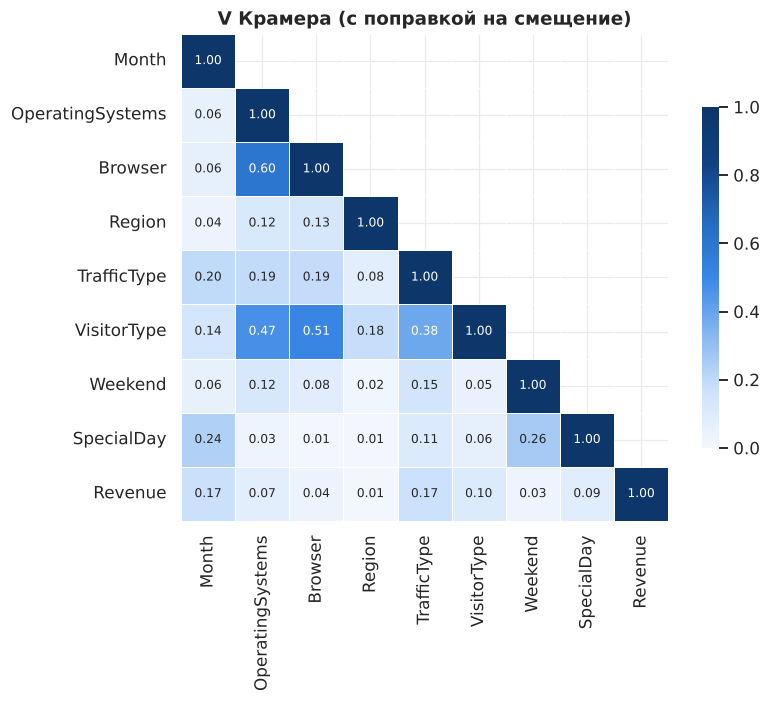

In [7]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return 0.0
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))      # поправка на смещение (Bergsma, 2013)
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1))))

cat_cols = NOMINAL + ["Weekend", "SpecialDay", TARGET]
V = pd.DataFrame(np.eye(len(cat_cols)), index=cat_cols, columns=cat_cols)
for a_, b_ in combinations(cat_cols, 2):
    V.loc[a_, b_] = V.loc[b_, a_] = cramers_v(df[a_], df[b_])

fig, ax = plt.subplots(figsize=(8, 6.5))
m2 = np.triu(np.ones_like(V, dtype=bool), k=1)
sns.heatmap(V, mask=m2, cmap=viz.SEQ, vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=0.5, linecolor="white", square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("V Крамера (с поправкой на смещение)")
plt.tight_layout(); plt.show()

**Номинальные признаки между собой и с `Revenue`.**
* Сильнее всего согласованы коды `OperatingSystems` и `Browser` (V = 0,60), а также `VisitorType` с `Browser` (0,51), с `OperatingSystems` (0,47) и с `TrafficType` (0,38).
* `SpecialDay` согласован с `Weekend` (0,26) и с `Month` (0,24): ненулевые значения `SpecialDay` встречаются только в феврале и мае (см. п. 6.1).
* С `Revenue`: `Month` и `TrafficType` — по 0,17, `VisitorType` — 0,10, `SpecialDay` — 0,09, `OperatingSystems` — 0,07, `Browser` — 0,04, `Weekend` — 0,03, `Region` — 0,01. Все значения невелики, это не противоречит lab2: χ² там «замечал» даже слабые различия из-за большого объёма выборки, а V показывает их силу.

In [8]:
pd.crosstab(df["OperatingSystems"], df["Browser"]).style.background_gradient(cmap=viz.SEQ, axis=None)

Browser,1,2,3,4,5,6,7,8,9,10,11,12,13
OperatingSystems,,,,,,,,,,,,,
1,2153,280,0,3,5,4,0,135,0,3,0,0,2
2,16,5059,1,732,430,155,39,0,0,160,0,4,5
3,1,2416,104,0,6,11,9,0,1,0,0,6,1
4,279,174,0,1,21,3,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,6,0,0
6,0,15,0,0,3,0,1,0,0,0,0,0,0
7,7,0,0,0,0,0,0,0,0,0,0,0,0
8,6,17,0,0,2,1,0,0,0,0,0,0,53


Таблица сопряжённости поясняет V = 0,60: коды ОС и браузера встречаются устойчивыми сочетаниями. Например, 2 153 из 2 585 сессий с ОС 1 — это браузер 1, 5 059 из 6 601 сессий с ОС 2 и 2 416 из 2 555 с ОС 3 — браузер 2, а 53 из 79 сессий с ОС 8 — браузер 13. Кроме того, браузер 13 встречается у 61 % посетителей типа `Other` (у остальных типов — меньше 1 %), отсюда связь `VisitorType` с `Browser`.

## 4. Числовой × категориальный: корреляционное отношение η
$\eta^2 = \dfrac{\sum_g n_g(\bar x_g - \bar x)^2}{\sum_i (x_i - \bar x)^2}$ — доля дисперсии числового признака, которая приходится на различия между группами категориального.

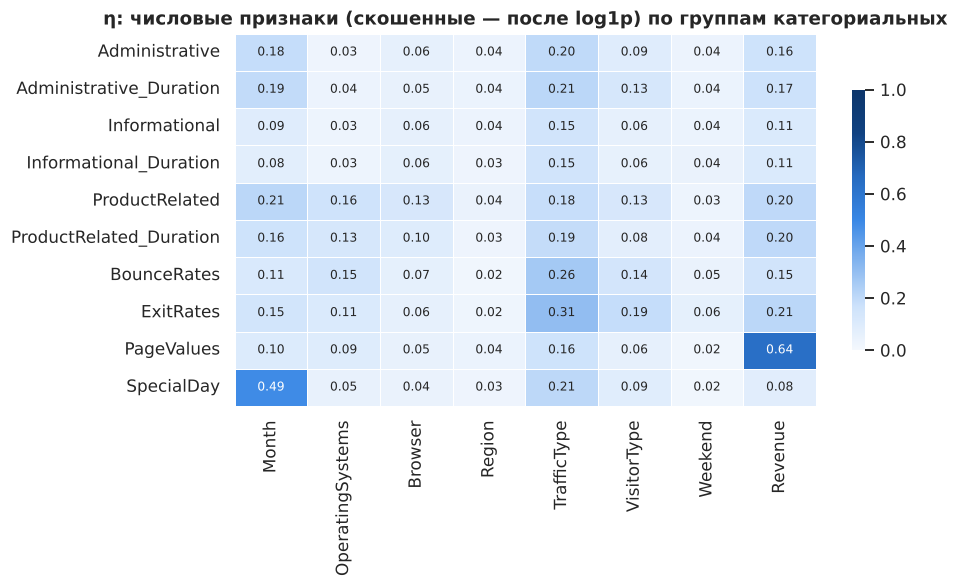

In [9]:
def corr_ratio(cat, x):
    x = np.asarray(x, dtype=float)
    groups = pd.Series(x).groupby(np.asarray(cat))
    ss_between = (groups.size() * (groups.mean() - x.mean()) ** 2).sum()
    ss_total = ((x - x.mean()) ** 2).sum()
    return float(np.sqrt(ss_between / ss_total))

cats_for_eta = NOMINAL + ["Weekend", TARGET]
from src.features import SKEWED
eta = pd.DataFrame({c: [corr_ratio(df[c], np.log1p(df[n]) if n in SKEWED else df[n]) for n in NUMERIC]
                    for c in cats_for_eta}, index=NUMERIC)
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(eta, cmap=viz.SEQ, vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("η: числовые признаки (скошенные — после log1p) по группам категориальных")
plt.tight_layout(); plt.show()

**Корреляционное отношение.**
* Самое большое значение — `PageValues` по классам `Revenue` (η = 0,64); у остальных числовых признаков η по `Revenue` от 0,08 до 0,21.
* `SpecialDay` по месяцам — η = 0,50 (тот же факт: ненулевые значения только в двух месяцах).
* `TrafficType` разделяет средние значения `ExitRates` (0,31) и `BounceRates` (0,27) сильнее остальных номинальных признаков; `Region` и `Weekend` почти ничего не объясняют ни в одном числовом признаке (η ≤ 0,06).

## 5. Единая матрица φK для всех признаков

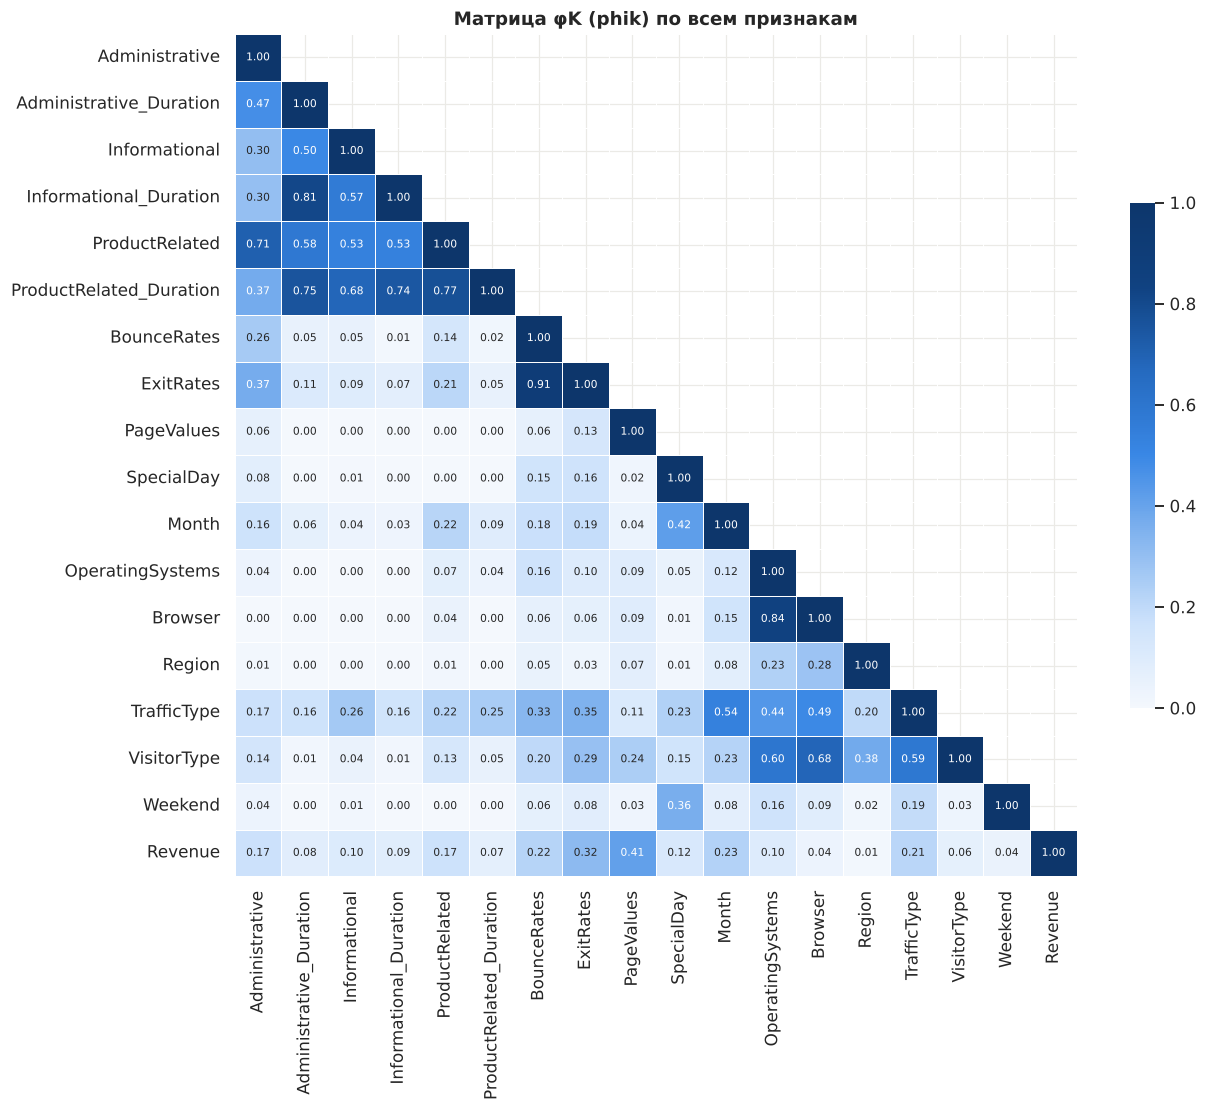

,PageValues,ExitRates,Month,BounceRates,TrafficType,Administrative,ProductRelated,SpecialDay,Informational,OperatingSystems,Informational_Duration,Administrative_Duration,ProductRelated_Duration,VisitorType,Weekend,Browser,Region
φK с Revenue,0.413,0.319,0.228,0.222,0.215,0.171,0.165,0.12,0.103,0.099,0.088,0.083,0.067,0.063,0.043,0.038,0.01


In [10]:
order = NUMERIC + NOMINAL + ["Weekend", TARGET]
P = phik_all.reindex(index=order, columns=order)
fig, ax = plt.subplots(figsize=(12, 10))
m3 = np.triu(np.ones_like(P, dtype=bool), k=1)
sns.heatmap(P, mask=m3, cmap=viz.SEQ, vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.5, linecolor="white", square=True, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Матрица φK (phik) по всем признакам")
plt.tight_layout(); plt.show()
phik_target = P[TARGET].drop(TARGET).sort_values(ascending=False)
phik_target.round(3).to_frame("φK с Revenue").T

**Матрица φK** собирает всё вместе и подтверждает картину, полученную разными коэффициентами:
* самые сильные пары — `BounceRates`–`ExitRates` (0,91), `OperatingSystems`–`Browser` (0,84), `Administrative_Duration`–`Informational_Duration` (0,81), `ProductRelated`–`ProductRelated_Duration` (0,77);
* `VisitorType` заметно согласован с кодами `Browser` (0,68), `OperatingSystems` (0,60) и `TrafficType` (0,59);
* по согласованности с `Revenue` признаки упорядочены так: `PageValues` (0,41) → `ExitRates` (0,32) → `Month` (0,23) → `BounceRates` (0,22) → `TrafficType` (0,21) → … → `Browser` (0,04) → `Region` (0,01).

## 6. Влияние пар факторов на целевую переменную
### 6.1. Тепловые карты доли покупок по сочетаниям двух признаков
Числовые признаки разбиты на интервалы: нули — отдельной группой (их много), ненулевые значения — по квартилям. В каждой клетке — доля сессий с покупкой, под ней мелко — число сессий; клетки, где сессий меньше 30, закрашены серым, чтобы не сравнивать ненадёжные оценки.

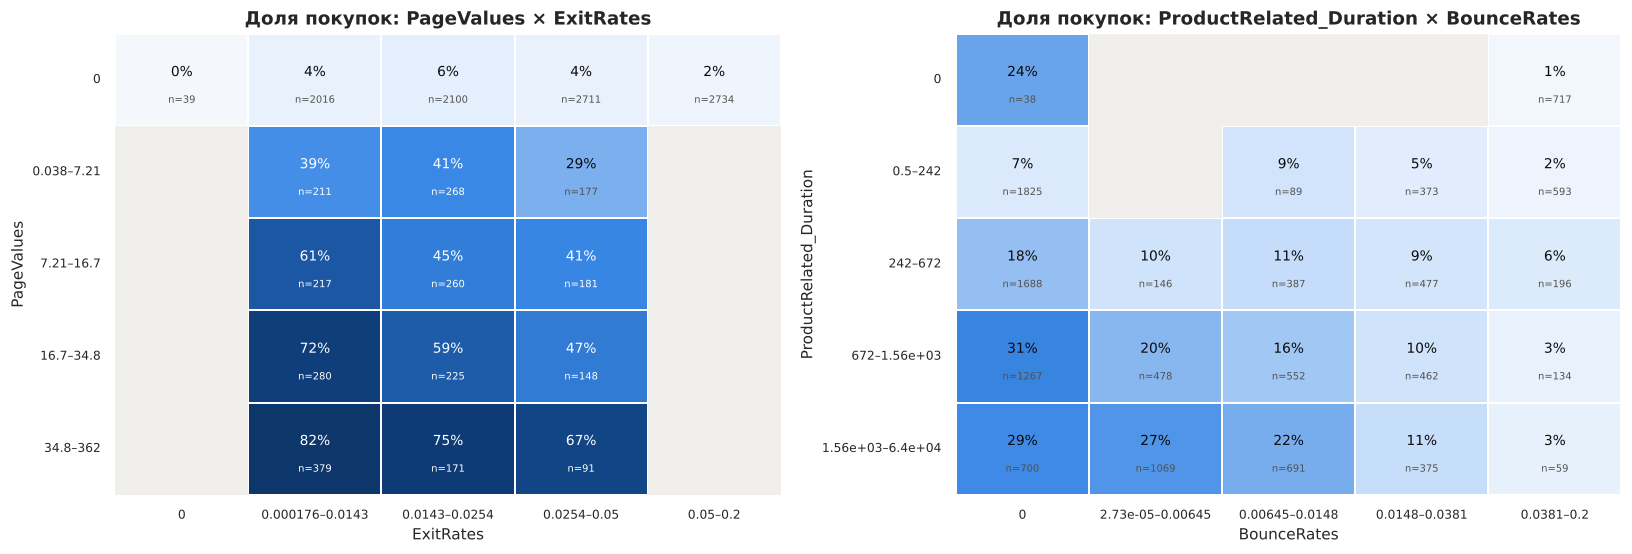

In [11]:
def bin_numeric(s, q=4):
    # ноль — отдельная группа, ненулевые значения — по квантилям; подписи — по фактическим границам
    out = pd.Series("0", index=s.index, dtype=object)
    pos = s[s > 0]
    edges = np.unique(np.quantile(pos, np.linspace(0, 1, q + 1)))
    labels = [f"{edges[i]:.3g}–{edges[i + 1]:.3g}" for i in range(len(edges) - 1)]
    out.loc[pos.index] = pd.cut(pos, edges, labels=labels, include_lowest=True).astype(str)
    return pd.Categorical(out, categories=["0"] + labels, ordered=True)

def pair_heatmap(a_, b_, ax, a_vals=None, b_vals=None, min_n=30):
    A = a_vals if a_vals is not None else df[a_]
    B = b_vals if b_vals is not None else df[b_]
    rate = pd.crosstab(A, B, values=df[TARGET], aggfunc="mean")
    cnt = pd.crosstab(A, B)
    shown = rate.where(cnt >= min_n)
    sns.heatmap(shown, cmap=viz.SEQ, vmin=0, vmax=max(0.6, np.nanmax(shown.values)), ax=ax, cbar=False,
                linewidths=1, linecolor="white")
    for i in range(rate.shape[0]):
        for j in range(rate.shape[1]):
            n = cnt.iloc[i, j]
            if n >= min_n:
                v = rate.iloc[i, j]
                ax.text(j + .5, i + .42, f"{v:.0%}", ha="center", va="center", fontsize=9,
                        color="white" if v > 0.35 else "#0b0b0b")
                ax.text(j + .5, i + .72, f"n={n}", ha="center", va="center", fontsize=6.5,
                        color="white" if v > 0.35 else "#52514e")
            else:
                ax.add_patch(plt.Rectangle((j, i), 1, 1, color="#f0efec", lw=0))
    ax.set_xlabel(b_); ax.set_ylabel(a_)
    ax.tick_params(labelsize=8)
    ax.tick_params(axis="x", rotation=0)
    return rate, cnt

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
pv_b = bin_numeric(df["PageValues"]); ex_b = bin_numeric(df["ExitRates"])
r1, c1 = pair_heatmap("PageValues", "ExitRates", axes[0], pv_b, ex_b)
axes[0].set_title("Доля покупок: PageValues × ExitRates")
pr_b = bin_numeric(df["ProductRelated_Duration"]); br_b = bin_numeric(df["BounceRates"])
r2, c2 = pair_heatmap("ProductRelated_Duration", "BounceRates", axes[1], pr_b, br_b)
axes[1].set_title("Доля покупок: ProductRelated_Duration × BounceRates")
plt.tight_layout(); plt.show()

**`PageValues` × `ExitRates` (слева).**
* Во всей строке `PageValues` = 0 доля покупок от 0 до 6 %, при любых значениях `ExitRates`.
* В строках с `PageValues` > 0 доля покупок растёт сверху вниз (с ростом `PageValues`) в каждом столбце: в первом столбце `ExitRates` 39 % → 61 % → 72 % → 82 %.
* Внутри каждой такой строки доля уменьшается слева направо (с ростом `ExitRates`): в нижней строке 82 % → 75 % → 67 %.
* Сочетаний «`PageValues` > 0 и `ExitRates` > 0,05» почти нет (меньше 30 сессий в каждой клетке).

**`ProductRelated_Duration` × `BounceRates` (справа).**
* В каждой строке доля покупок уменьшается слева направо: например, при длительности 1 560–64 000 с — 29 % → 27 % → 22 % → 11 % → 3 %.
* При одинаковом `BounceRates` = 0 доля покупок различается по строкам от 7 % до 31 %.
* Строка с нулевым временем на товарных страницах (755 сессий) почти целиком приходится на максимальные `BounceRates` (717 сессий, доля покупок 1 %).

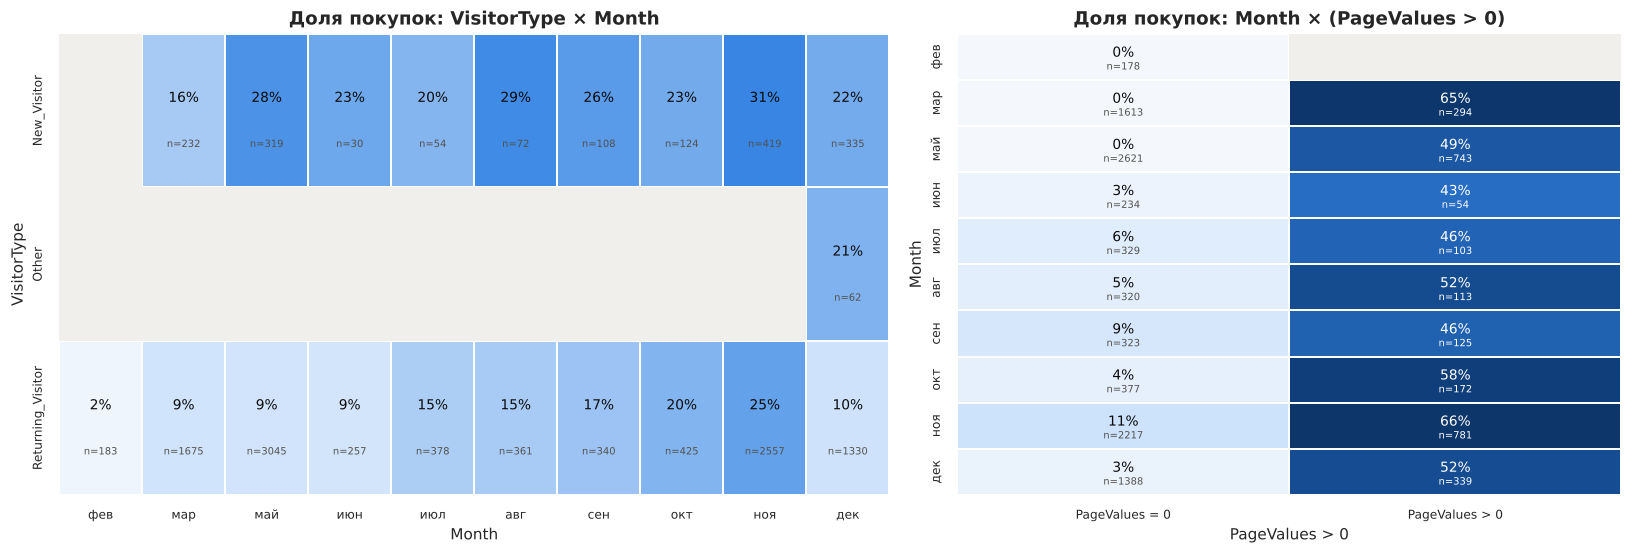

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
month_lbl = pd.Categorical(df["Month"].map(MONTH_RU), categories=[MONTH_RU[m] for m in MONTH_ORDER], ordered=True)
pv_flag = np.where(df["PageValues"] > 0, "PageValues > 0", "PageValues = 0")
r3, c3 = pair_heatmap("VisitorType", "Month", axes[0], df["VisitorType"].astype(str), month_lbl)
axes[0].set_title("Доля покупок: VisitorType × Month")
r4, c4 = pair_heatmap("Month", "PageValues > 0", axes[1], month_lbl, pv_flag)
axes[1].set_title("Доля покупок: Month × (PageValues > 0)")
plt.tight_layout(); plt.show()

**`VisitorType` × `Month` (слева).** В каждом месяце, где есть обе группы, доля покупок у новых посетителей выше, чем у вернувшихся: март — 16 % и 9 %, май — 28 % и 9 %, ноябрь — 31 % и 25 %, декабрь — 22 % и 10 %. В феврале новый посетитель всего один; тип `Other` встречается только в июне (1), ноябре (22) и декабре (62).

**`Month` × (`PageValues` > 0) (справа).** Сессий с нулевым `PageValues` и покупкой нет совсем в феврале, марте и мае (0 из 178, 1 613 и 2 621 сессии), в остальных месяцах таких покупок 3–11 % (максимум — ноябрь, 245 из 2 217). При `PageValues` > 0 доля покупок от 43 % (июнь) до 66 % (ноябрь). Это особенность данных, которую стоит помнить при интерпретации модели: в части месяцев покупка без ненулевого `PageValues` в выборке не встречается вообще.

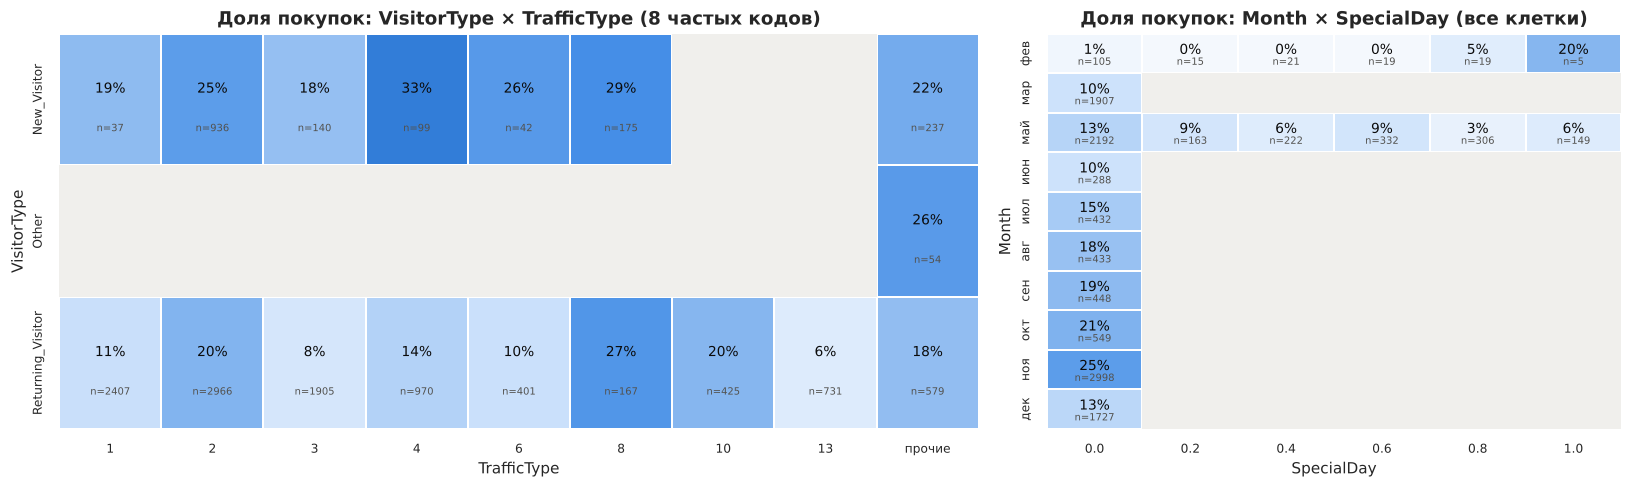

In [13]:
tt = df["TrafficType"].astype(int)
top_tt = tt.value_counts().index[:8]
tt_lbl = pd.Categorical(np.where(tt.isin(top_tt), tt.astype(str), "прочие"),
                        categories=[str(t) for t in sorted(top_tt)] + ["прочие"], ordered=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
r5, c5 = pair_heatmap("VisitorType", "TrafficType", axes[0], df["VisitorType"].astype(str), tt_lbl)
axes[0].set_title("Доля покупок: VisitorType × TrafficType (8 частых кодов)")
sd = df["SpecialDay"].map(lambda v: f"{v:.1f}")
r6, c6 = pair_heatmap("Month", "SpecialDay", axes[1], month_lbl, sd, min_n=1)
axes[1].set_title("Доля покупок: Month × SpecialDay (все клетки)")
plt.tight_layout(); plt.show()

**`VisitorType` × `TrafficType` (слева).** Для каждого из шести кодов, где обе группы представлены хотя бы 30 сессиями, доля покупок у новых посетителей выше, чем у вернувшихся (например, код 4 — 33 % и 14 %, код 6 — 26 % и 10 %, код 3 — 18 % и 8 %); у кода 8 значения близки (29 % и 27 %). Коды 10 и 13 почти не встречаются у новых посетителей.

**`Month` × `SpecialDay` (справа, показаны все клетки).** Ненулевой `SpecialDay` бывает только в феврале (79 сессий) и мае (1 172 сессии). В мае доля покупок при `SpecialDay` > 0 — от 3 % до 9 %, при `SpecialDay` = 0 — 13 %. Значит, сравнение «`SpecialDay` > 0 против 0» из lab2 по сути сравнивает часть мая и февраля со всеми остальными месяцами — признаки `SpecialDay` и `Month` нельзя рассматривать по отдельности.

### 6.2. Диаграммы рассеяния по классам
Чтобы классы не перекрывали друг друга, «покупки» рисуются поверх; взята случайная подвыборка 5 000 сессий.

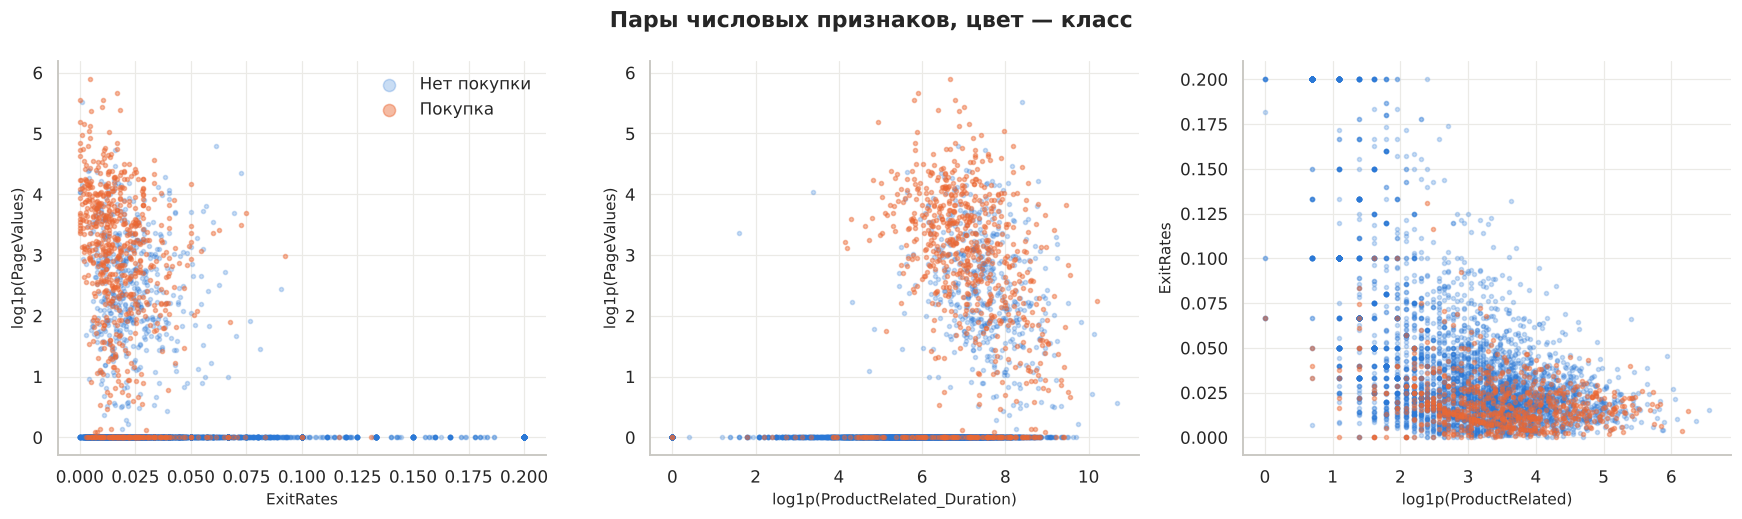

In [14]:
s = df.sample(5000, random_state=1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
specs = [("ExitRates", "PageValues", False, True), ("ProductRelated_Duration", "PageValues", True, True),
         ("ProductRelated", "ExitRates", True, False)]
for a, (xc, yc, lx_, ly_) in zip(axes, specs):
    for cls, z in [(0, 1), (1, 2)]:
        part = s[s[TARGET] == cls]
        xv = np.log1p(part[xc]) if lx_ else part[xc]
        yv = np.log1p(part[yc]) if ly_ else part[yc]
        a.scatter(xv, yv, s=7, alpha=0.45 if cls else 0.25, zorder=z,
                  color=viz.CLASS_PALETTE[cls], label=viz.class_name([cls])[0])
    a.set_xlabel(("log1p(" + xc + ")") if lx_ else xc)
    a.set_ylabel(("log1p(" + yc + ")") if ly_ else yc)
axes[0].legend(markerscale=3, loc="upper right")
plt.suptitle("Пары числовых признаков, цвет — класс", fontweight="bold")
plt.tight_layout(); plt.show()

* `ExitRates` × `PageValues`: «покупки» сосредоточены в области `PageValues` > 0 и `ExitRates` < 0,05; на линии `PageValues` = 0 оранжевых точек мало, и они рассыпаны по всему диапазону `ExitRates`.
* `ProductRelated_Duration` × `PageValues`: среди сессий с `PageValues` > 0 «покупки» встречаются при длительности от `log1p` ≈ 4 (≈ 55 с) и выше; облака классов перекрываются.
* `ProductRelated` × `ExitRates`: облака двух классов почти полностью накладываются, «покупки» смещены к меньшим `ExitRates` и большему числу страниц; верхняя часть графика (`ExitRates` > 0,1) почти целиком синяя.

### 6.3. Насколько пара признаков вместе описывает `Revenue`
Для каждой пары признаков строю составную категорию «интервал признака 1 × интервал признака 2» (числовые признаки разбиты как выше: ноль + квартили ненулевых значений; у номинальных категории реже 1 % объединены в «прочие») и считаю V Крамера этой составной категории с `Revenue`. Сравниваю с V каждого признака по отдельности:

* **V пары** — насколько хорошо сочетание двух признаков разделяет классы;
* **прирост** = V пары − max(V₁, V₂) — что добавляет второй признак к лучшему из двух.

Это описательная мера на интервалах, а не модель: она показывает, в каких парах доля покупок по клеткам различается сильнее, чем по каждому признаку отдельно.

V Крамера отдельных признаков (на интервалах):


,PageValues,ExitRates,ProductRelated_Duration,ProductRelated,BounceRates,Month,Administrative,Administrative_Duration,TrafficType,Informational,Informational_Duration,VisitorType,SpecialDay,OperatingSystems,Weekend,Browser,Region
V,0.635,0.248,0.213,0.193,0.186,0.175,0.173,0.168,0.167,0.114,0.113,0.104,0.086,0.075,0.028,0.02,0.01


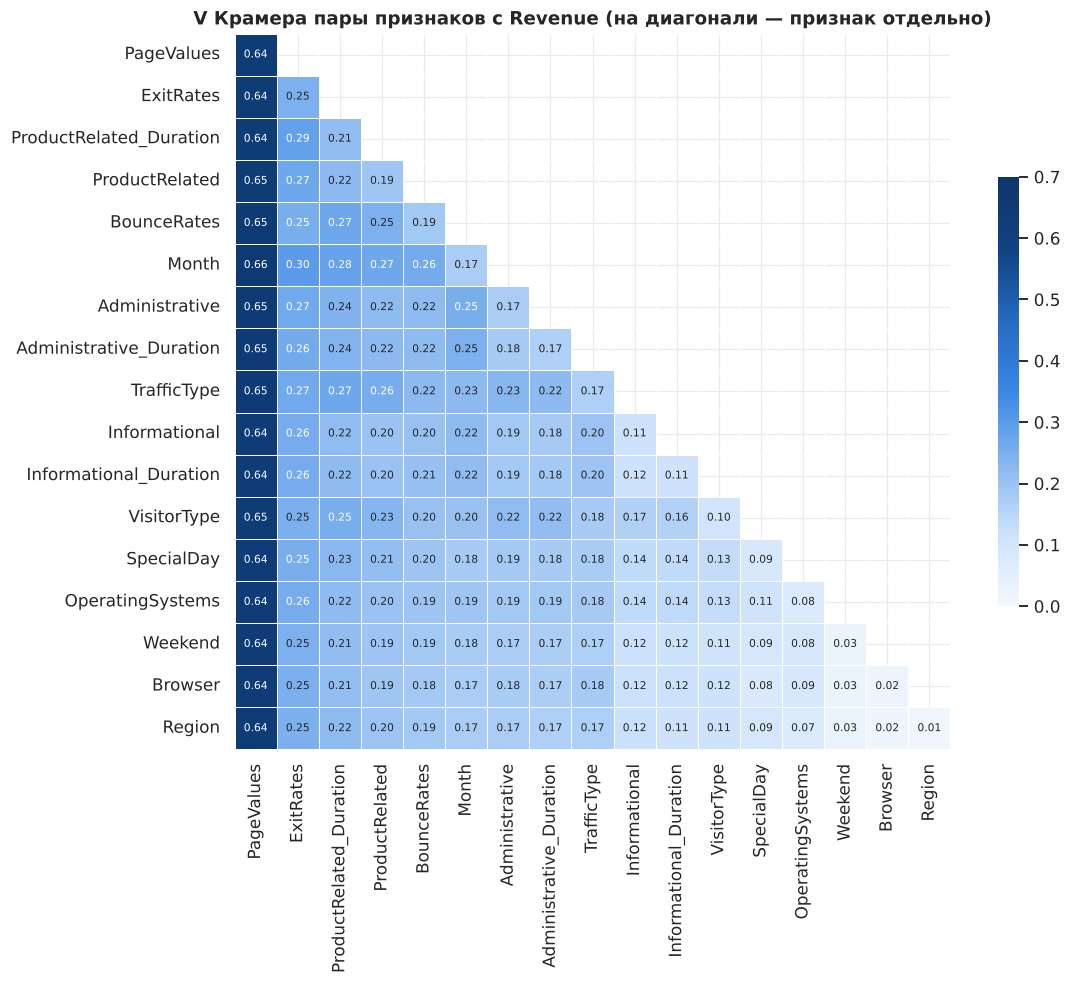

In [15]:
def to_bins(c):
    if c in NUMERIC and c != "SpecialDay":
        return pd.Series(bin_numeric(df[c]), index=df.index).astype(str)
    s_ = df[c].astype(str)
    freq = s_.value_counts(normalize=True)
    return s_.where(s_.map(freq) >= 0.01, "прочие")

feat = NUMERIC + NOMINAL + ["Weekend"]
B = {c: to_bins(c) for c in feat}
v1 = {c: cramers_v(B[c], df[TARGET]) for c in feat}
rows = []
for a_, b_ in combinations(feat, 2):
    vp = cramers_v(B[a_] + " | " + B[b_], df[TARGET])
    rows.append({"признак 1": a_, "признак 2": b_, "V₁": v1[a_], "V₂": v1[b_], "V пары": vp,
                 "прирост": vp - max(v1[a_], v1[b_])})
pair_v = pd.DataFrame(rows)

single = pd.Series(v1).sort_values(ascending=False)
print("V Крамера отдельных признаков (на интервалах):")
display(single.round(3).to_frame("V").T)

M = pd.DataFrame(np.nan, index=feat, columns=feat)
for r in rows:
    M.loc[r["признак 1"], r["признак 2"]] = M.loc[r["признак 2"], r["признак 1"]] = r["V пары"]
for c in feat:
    M.loc[c, c] = v1[c]
order2 = single.index
M = M.loc[order2, order2]
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(M, mask=np.triu(np.ones_like(M, dtype=bool), k=1), cmap=viz.SEQ, vmin=0, vmax=0.7,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, linecolor="white", square=True,
            cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("V Крамера пары признаков с Revenue (на диагонали — признак отдельно)")
plt.tight_layout(); plt.show()

In [16]:
print("Пары с наибольшим V (описывают Revenue сильнее всего):")
display(pair_v.sort_values("V пары", ascending=False).head(10).round(3).reset_index(drop=True))
print("Пары с наибольшим приростом к лучшему из двух признаков:")
display(pair_v.sort_values("прирост", ascending=False).head(10).round(3).reset_index(drop=True))

Пары с наибольшим V (описывают Revenue сильнее всего):


,признак 1,признак 2,V₁,V₂,V пары,прирост
0,PageValues,Month,0.635,0.175,0.657,0.022
1,BounceRates,PageValues,0.186,0.635,0.652,0.017
2,Administrative,PageValues,0.173,0.635,0.649,0.013
3,Administrative_Duration,PageValues,0.168,0.635,0.646,0.011
4,PageValues,TrafficType,0.635,0.167,0.645,0.010
5,ProductRelated,PageValues,0.193,0.635,0.645,0.010
6,PageValues,VisitorType,0.635,0.104,0.645,0.010
7,ExitRates,PageValues,0.248,0.635,0.644,0.009
8,ProductRelated_Duration,PageValues,0.213,0.635,0.643,0.008
9,Informational,PageValues,0.114,0.635,0.640,0.004


Пары с наибольшим приростом к лучшему из двух признаков:


,признак 1,признак 2,V₁,V₂,V пары,прирост
0,Administrative,Month,0.173,0.175,0.252,0.077
1,ProductRelated,Month,0.193,0.175,0.270,0.076
2,BounceRates,Month,0.186,0.175,0.261,0.074
3,Administrative_Duration,Month,0.168,0.175,0.247,0.072
4,ProductRelated_Duration,Month,0.213,0.175,0.282,0.069
5,ProductRelated,TrafficType,0.193,0.167,0.256,0.063
6,Administrative,TrafficType,0.173,0.167,0.230,0.057
7,ProductRelated_Duration,BounceRates,0.213,0.186,0.269,0.056
8,ProductRelated,BounceRates,0.193,0.186,0.248,0.055
9,ProductRelated_Duration,TrafficType,0.213,0.167,0.268,0.055


**Что показывает V Крамера для пар.**
* Отдельно сильнее всего `Revenue` описывает `PageValues` (V = 0,64); остальные признаки — от 0,25 (`ExitRates`) до 0,01 (`Region`).
* Все 10 самых сильных пар содержат `PageValues` (V пары 0,64–0,66), а второй признак добавляет к нему не больше 0,022 (лучшее сочетание — с `Month`). На интервалах `PageValues` второй признак почти ничего не добавляет к разделению классов.
* Наибольший **прирост** к лучшему из двух признаков дают пары с `Month`: `Administrative` × `Month` (+0,077), `ProductRelated` × `Month` (+0,076), `BounceRates` × `Month` (+0,074), `Administrative_Duration` × `Month` (+0,072), `ProductRelated_Duration` × `Month` (+0,069); далее — пары с `TrafficType` и пара `ProductRelated(_Duration)` × `BounceRates`. В этих парах V сочетания заметно выше, чем у каждого признака по отдельности, — то есть доля покупок по клеткам таких таблиц различается сильнее, чем по строкам или столбцам.
* Пары с `Region`, `Browser` и `Weekend` почти не отличаются от второго признака пары.

## 7. Итоги

**Итоги lab3 (наблюдения):**

1. **Выбор коэффициента важен.** На скошенных признаках с большим числом нулей Пирсон занижает согласованность «число страниц — время» (0,60 против ρ = 0,94) и завышает её для `BounceRates`–`ExitRates` (0,91 против 0,60) из-за 700 одинаковых сессий в точке (0,2; 0,2). Ранговые коэффициенты и φK дают более устойчивую картину; при этом φK для скошенных признаков зависит от способа бинирования.
2. **Сильно согласованные пары признаков:** три пары «счётчик — длительность», `BounceRates`–`ExitRates`, `OperatingSystems`–`Browser`; `VisitorType` согласован с кодами браузера, ОС и трафика; `SpecialDay` — с `Month` (ненулевые значения только в феврале и мае).
3. **Согласованность с `Revenue`** по всем мерам: `PageValues` ≫ `ExitRates` > `Month`, `BounceRates`, `TrafficType`, `ProductRelated(_Duration)`, `Administrative` > прочие; `Region`, `Browser`, `Weekend` — около нуля.
4. **Пары факторов:**
   * в таблице `PageValues` × `ExitRates` доля покупок меняется монотонно по обоим направлениям — от 0–6 % (`PageValues` = 0) до 82 % (высокий `PageValues`, низкий `ExitRates`);
   * в таблице `ProductRelated_Duration` × `BounceRates` доля покупок в каждой строке падает с ростом `BounceRates`;
   * новые посетители имеют более высокую долю покупок, чем вернувшиеся, в каждом месяце и почти в каждом источнике трафика;
   * в феврале, марте и мае нет ни одной покупки среди сессий с `PageValues` = 0;
   * сильнее всего «сочетание лучше отдельных признаков» проявляется в парах с `Month` и `TrafficType`.

**Что передаю в подготовку данных и моделирование:** не использовать label encoding для кодов (lab4); учитывать мультиколлинеарность для линейных моделей (регуляризация); проверить, насколько модель зависит от `PageValues`, — этот признак сильнее всех остальных вместе взятых описывает целевую переменную на этапе EDA, и это стоит отдельно разобрать при интерпретации моделей (lab5).